# Manhattan Rats and a Barrier to Migration

Compare pairs at the same geographic separation. A barrier can make
their ancestors less likely to meet, increasing genetic differences.
First simulate this pattern on a line of demes. Then read the effective
migration surfaces fitted to SNPs and sample locations in two studies.

In [1]:
library(hpgR)
options(repr.plot.width = 10, repr.plot.height = 4.5,
        repr.plot.pointsize = 14, warn = 1)
drawFigure <- function(name, draw, width = 10, height = 4.5) {
    options(repr.plot.width = width, repr.plot.height = height)
    directory <- Sys.getenv("P8149_FIGURE_DIR")
    if (nzchar(directory)) {
        dir.create(directory, recursive = TRUE, showWarnings = FALSE)
        pdf(file.path(directory, paste0(name, ".pdf")), width = width, height = height)
        tryCatch(draw(legend_spacing = 1), finally = dev.off())
    }
    if ("IRkernel" %in% loadedNamespaces()) {
        par(bg = "white")
        draw(legend_spacing = 2.1)
    }
    invisible(NULL)
}

blue <- "#1D4F91"
red <- "#D14124"

## A known barrier in a stepping-stone simulation

Let $\Pi=(\pi_{ij})$, where $\pi_{ij}$ is the probability that an offspring copy in deme $i$ draws its parent from deme $j$.
At an independent locus, draw
$K_{i,t+1}\mid\mathbf p_t\sim\operatorname{Binomial}(2N_e,(\Pi\mathbf p_t)_i)$
and set $p_{i,t+1}=K_{i,t+1}/(2N_e)$.

Use the lecture's ten demes, $N_e=120$ per deme, 65 generations and 48 panels
of 800 independent loci. Each edge has migration probability 0.12 in each
direction. The barrier lowers the edge between demes 5 and 6 to 0.006. In an
interior deme with two open edges the total immigrant probability is 0.24.
For each panel, the two histories start with the same allele frequencies.

In [2]:
Ne <- 120L
generations <- 65L
sites <- 800L
panels <- 48L
edgeRates <- rep(0.12, 9L)
barrierRates <- replace(edgeRates, 5L, 0.006)
# A row gives parental sources for the destination deme.
migrationModels <- lapply(list(edgeRates, barrierRates), function(rates) {
    migration <- matrix(0, 10, 10)
    edges <- cbind(1:9, 2:10)
    migration[edges] <- migration[edges[, 2:1]] <- rates
    diag(migration) <- 1 - rowSums(migration)
    migration
})
pair <- combn(10, 2)
distance <- pair[2, ] - pair[1, ]
crosses <- pair[1, ] <= 5L & pair[2, ] > 5L

set.seed(814910)
spatial <- replicate(panels, {
    start <- matrix(rep(runif(sites, .1, .9), each = 10), nrow = 10)
    vapply(migrationModels, function(migration) {
        p <- simulateDemeFrequencies(start, Ne, migration, generations)
        divergence <- rowMeans((p[pair[1, ], ] - p[pair[2, ], ])^2)
        sapply(1:4, function(d) c(
            within = mean(divergence[distance == d & !crosses]),
            across = mean(divergence[distance == d & crosses])))
    }, matrix(0, 2, 4))
})
spatial <- array(spatial, dim = c(2, 4, 2, panels))
stopifnot(all(vapply(migrationModels, function(migration) {
    isTRUE(all.equal(rowSums(migration), rep(1, 10L))) && all(migration >= 0)
}, logical(1L))))
spatialMean <- apply(spatial, 1:3, mean)
spatialLow <- apply(spatial, 1:3, quantile, probs = 0.05)
spatialHigh <- apply(spatial, 1:3, quantile, probs = 0.95)
stopifnot(abs(spatialMean[2, 1, 1] - spatialMean[1, 1, 1]) < 0.005,
          all(spatialMean[2, , 2] > spatialMean[1, , 2]))

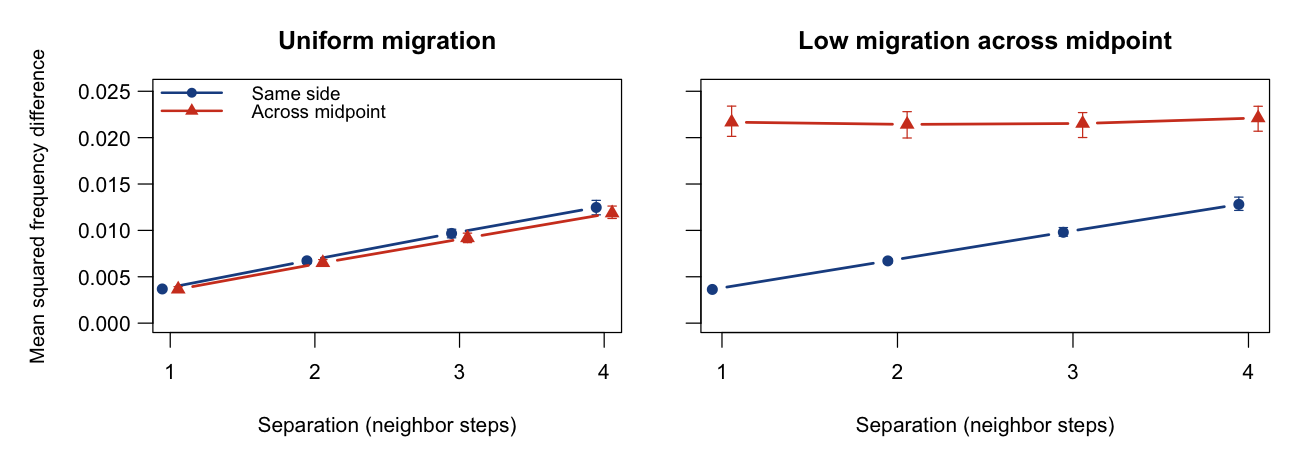

In [3]:
drawFigure("stepping_stone_barrier_simulation", function(legend_spacing) {
    par(mfrow = c(1, 2), las = 1, cex = 1.05, mgp = c(2.55, 0.75, 0))
    for (model in 1:2) {
        par(mar = c(4.2, if (model == 1) 5.2 else 1.8, 2.7, 0.9))
        plot(1:4, spatialMean[1, , model], type = "n", xaxt = "n", yaxt = "n",
             ylim = c(0, max(spatialHigh) * 1.08),
             xlab = "Separation (neighbor steps)", ylab = "",
             main = c("Uniform migration", "Low migration across midpoint")[model])
        axis(1, at = 1:4)
        axis(2, labels = model == 1)
        for (group in 1:2) {
            color <- c(blue, red)[group]
            x <- 1:4 + c(-0.055, 0.055)[group]
            arrows(x, spatialLow[group, , model], x, spatialHigh[group, , model],
                   angle = 90, code = 3, length = 0.035, col = color)
            lines(x, spatialMean[group, , model], type = "b", pch = c(16, 17)[group],
                  lwd = 2.2, col = color)
        }
        if (model == 1) {
            mtext("Mean squared frequency difference", side = 2, line = 3.5, las = 0)
            legend("topleft", c("Same side", "Across midpoint"), col = c(blue, red),
                   pch = c(16, 17), lty = 1, lwd = 2, bty = "n", cex = 0.90,
                   y.intersp = legend_spacing)
        }
    }
}, width = 10.8, height = 3.8)

For each pair of demes, the plot averages squared allele-frequency
differences across loci. Points give panel means, and bars give the 5th and
95th percentiles. Compare pairs at the same number of neighbor steps.
The across-midpoint pairs show an excess when the simulated edge is weak.

## How EEMS reads SNPs and locations

The input is one location per sampled individual and diploid allele counts
$g_{i\ell}\in\{0,1,2\}$ at $L$ SNPs. Assign each individual to its nearest
deme on a two-dimensional grid. For individuals $i$ and $j$, form

$$
D_{ij}=\frac{1}{L}\sum_{\ell=1}^L(g_{i\ell}-g_{j\ell})^2.
$$

If their demes are $\alpha$ and $\beta$, the lecture writes the model as

$$
E[D_{ij}\mid\mathbf m,\mathbf q,\sigma^2]
=\sigma^2\left[R_{\alpha\beta}(\mathbf m)
+\frac{q_\alpha+q_\beta}{2}\right].
$$

The resistance $R_{\alpha\beta}$ combines all routes across the grid.
Higher migration rates on edges give lower resistance. The $q$ terms account
for local diversity and $\sigma^2$ scales SNP differences. EEMS fits the
whole dissimilarity matrix. Blue and orange show higher and lower effective
migration relative to the habitat-wide rate, on a $\log_{10}$ scale.
The simulation above produces deme frequencies. The published EEMS fits
below use pairwise dissimilarities of individuals.

## Western Europe

Petkova, Novembre, and Stephens analyzed 1,201 people from 13 Western European
countries and assigned locations by nationality. The surface places a band of
lower effective migration along the Alps and higher effective migration around
the North Sea. [Petkova et al. (2016), Fig. 5a](https://www.nature.com/articles/ng.3464/figures/5).

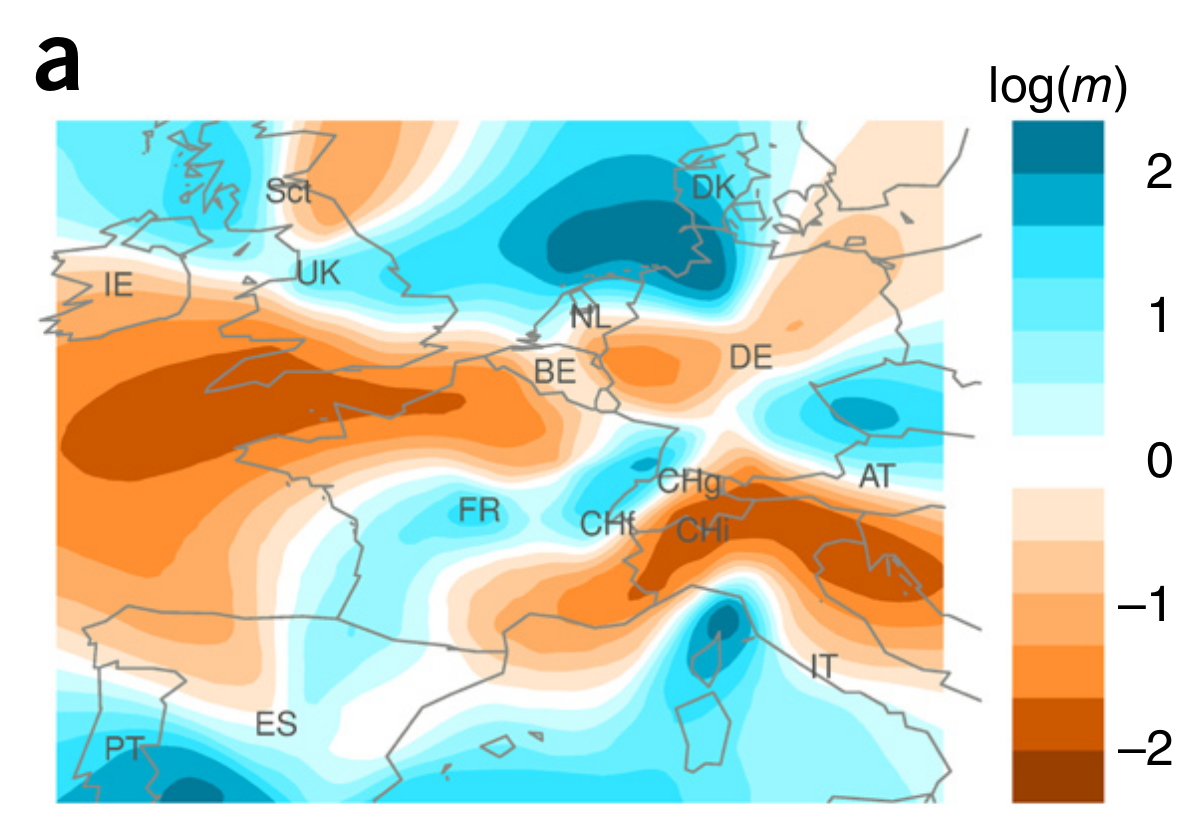

## Brown rats in Manhattan

Combs et al. genotyped 262 rats at 61,401 SNPs. They compared the distance
between trap locations for pairs in each inferred kinship class.

| Kinship class | Pairs | Mean distance | Median distance |
| --- | ---: | ---: | ---: |
| First-order relatives | 91 | 45 m | 14 m |
| Second-order relatives | 76 | 139 m | 24 m |
| Distantly related pairs | 30 | 1,259 m | 328 m |

The 45 m measures separation between traps. For the citywide analysis
the authors excluded close relatives, leaving 198 rats, and fit EEMS on 60
putative demes. [Combs et al. (2018), Table 2 and Fig. 4d](https://nycevolution.org/pdf/Combs_etal2017MolecularEcology.pdf#page=8).

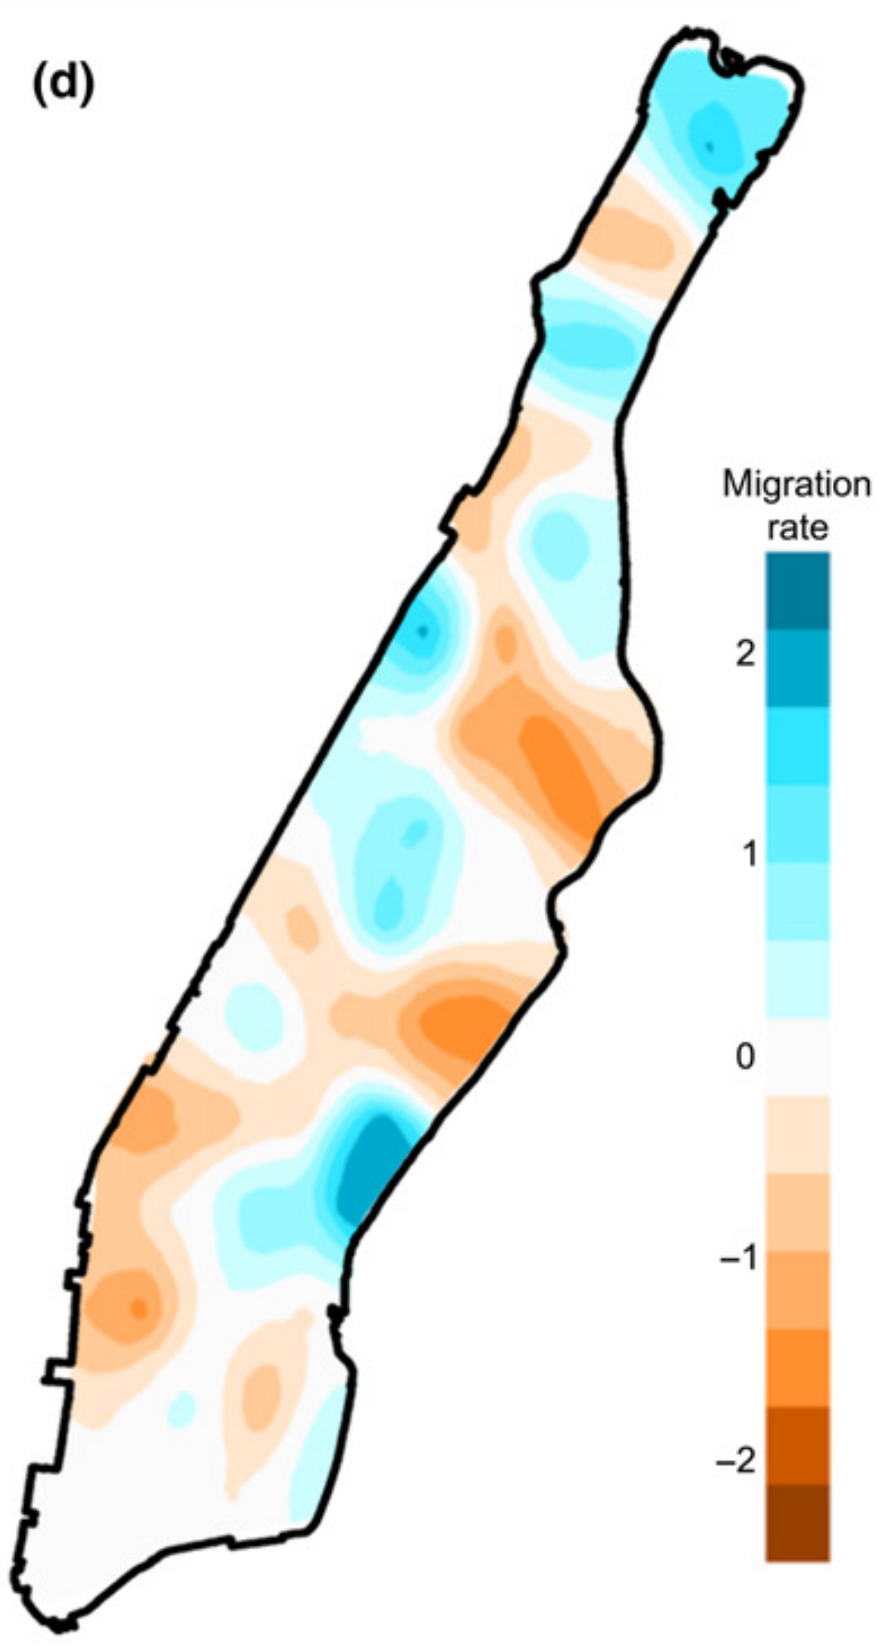

The orange band near Midtown overlaps the Uptown–Downtown break seen
in spatial PCA. Differentiation between the groups was modest
($F_{ST}=0.01$). The surface summarizes relative connectivity. Habitat,
local density, and past population separation can all affect it.

Next: [Archaic Gene Flow and Shared Alleles](P8149_Lecture_10_Archaic_Gene_Flow.ipynb).
Use ancestor times and shared alleles to ask about past contact after a split.